## Blenda Mutuma
## Final Project

Risk Factors Associated with Low Infant Birth Weight
Summary: The data on 189 births were collected at Baystate Medical Center, Springfield, Mass. during 1986. The dataset contains an indicator of low infant birth weight as a response and several risk factors associated with low birth weight. The actual birth weight is also included in the dataset.

Data description: The dataset consists of the following 10 variables:

· low: indicator of birth weight less than 2.5kg

· age: mother's age in years

· lwt: mother's weight in pounds at last menstrual period

· race: mothers race ("white", "black", "other")

· smoke: smoking status during pregnancy

· ht: history of hypertension

· ui: presence of uterine irritability

· ftv: physician visits during the first trimester (Yes or No)

· ptl: Previous premature labours (Yes or No)

· bwt: birth weight in grams

In [1]:
import warnings
warnings.filterwarnings('ignore')

In [2]:
# import library
import pandas as pd
import seaborn as sns

In [3]:
#load 'low_birth_weight_project.csv' 
df= pd.read_csv('low_birth_weight_project.csv')

In [4]:
#check first/last rows 
df

,low,age,lwt,race,bwt,weight,smoke,ht,ui,ftv,ptl
0,0,19,182,black,2523.0,no,no,no,yes,no,no
1,0,33,155,other,2551.0,no,no,no,no,yes,no
2,0,20,105,white,2557.0,no,yes,no,no,yes,no
3,0,21,108,white,2594.0,no,yes,no,yes,yes,no
4,0,18,107,white,2600.0,no,yes,no,yes,no,no
...,...,...,...,...,...,...,...,...,...,...,...
184,1,28,95,white,2466.0,yes,yes,no,no,yes,no
185,1,14,100,other,2495.0,yes,no,no,no,yes,no
186,1,23,94,other,2495.0,yes,yes,no,no,no,no
187,1,17,142,black,2495.0,yes,no,yes,no,no,no


## Exploratory Data Analysis

In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
low,189.0,0.312169,0.464609,0.0,0.0,0.0,1.0,1.0
age,189.0,23.238095,5.298678,14.0,19.0,23.0,26.0,45.0
lwt,189.0,129.687831,30.647150,80.0,110.0,121.0,140.0,250.0
bwt,189.0,2944.656085,729.022417,709.0,2414.0,2977.0,3475.0,4990.0


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 189 entries, 0 to 188
Data columns (total 11 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   low     189 non-null    int64  
 1   age     189 non-null    int64  
 2   lwt     189 non-null    int64  
 3   race    189 non-null    object 
 4   bwt     189 non-null    float64
 5   weight  189 non-null    object 
 6   smoke   189 non-null    object 
 7   ht      189 non-null    object 
 8   ui      189 non-null    object 
 9   ftv     189 non-null    object 
 10  ptl     189 non-null    object 
dtypes: float64(1), int64(3), object(7)
memory usage: 16.4+ KB


In [7]:
# Check the count of unique values 
cat_cols=df.select_dtypes('object')
for i in cat_cols:
    print(cat_cols[i].value_counts(normalize=True))
    print('-'*30)

race
white    0.507937
other    0.354497
black    0.137566
Name: proportion, dtype: float64
------------------------------
weight
no     0.687831
yes    0.312169
Name: proportion, dtype: float64
------------------------------
smoke
no     0.608466
yes    0.391534
Name: proportion, dtype: float64
------------------------------
ht
no     0.936508
yes    0.063492
Name: proportion, dtype: float64
------------------------------
ui
no     0.851852
yes    0.148148
Name: proportion, dtype: float64
------------------------------
ftv
no     0.529101
yes    0.470899
Name: proportion, dtype: float64
------------------------------
ptl
no     0.84127
yes    0.15873
Name: proportion, dtype: float64
------------------------------


## RENAME THE COLUMN TITLES

In [8]:
# rename 'low' to 'low_birth_weight'
df=df.rename(columns={'low' : 'low_birth_weight'})

In [9]:
# rename 'age' to 'age_of_mother'
df=df.rename(columns={'age' : 'age_of_mother'})

In [10]:
# rename 'lwt' to'last_menstrual_weight'}
df=df.rename(columns={'lwt' : 'last_menstrual_weight'})

In [11]:
#rename 'race' to 'mother_race
df=df.rename(columns={'race' : 'mother_race'})

In [12]:
# rename 'smoke' to'smoking_status'
df=df.rename(columns={'smoke' : 'smoking_status'})

In [13]:
#rename 'ht' to 'hypertension_history'
df=df.rename(columns={'ht' : 'hypertension_history'})

In [14]:
#rename 'ui'to 'uterine_irritability'
df=df.rename(columns={'ui' : 'uterine_irritability'})

In [15]:
#rename 'ftv' to 'physician_visit'
df=df.rename(columns={'ftv' : 'physician_visit'})

In [16]:
#rename 'ptl' to 'premature_labors'
df=df.rename(columns={'ptl' : 'premature_labors'})

In [17]:
#rename 'bwt' to 'birth_weight_grams'
df=df.rename(columns={'bwt' : 'birth_weight_grams'})

In [18]:
#Show first /last row
df

,low_birth_weight,age_of_mother,last_menstrual_weight,mother_race,birth_weight_grams,weight,smoking_status,hypertension_history,uterine_irritability,physician_visit,premature_labors
0,0,19,182,black,2523.0,no,no,no,yes,no,no
1,0,33,155,other,2551.0,no,no,no,no,yes,no
2,0,20,105,white,2557.0,no,yes,no,no,yes,no
3,0,21,108,white,2594.0,no,yes,no,yes,yes,no
4,0,18,107,white,2600.0,no,yes,no,yes,no,no
...,...,...,...,...,...,...,...,...,...,...,...
184,1,28,95,white,2466.0,yes,yes,no,no,yes,no
185,1,14,100,other,2495.0,yes,no,no,no,yes,no
186,1,23,94,other,2495.0,yes,yes,no,no,no,no
187,1,17,142,black,2495.0,yes,no,yes,no,no,no


In [19]:
#show basic info
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 189 entries, 0 to 188
Data columns (total 11 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   low_birth_weight       189 non-null    int64  
 1   age_of_mother          189 non-null    int64  
 2   last_menstrual_weight  189 non-null    int64  
 3   mother_race            189 non-null    object 
 4   birth_weight_grams     189 non-null    float64
 5   weight                 189 non-null    object 
 6   smoking_status         189 non-null    object 
 7   hypertension_history   189 non-null    object 
 8   uterine_irritability   189 non-null    object 
 9   physician_visit        189 non-null    object 
 10  premature_labors       189 non-null    object 
dtypes: float64(1), int64(3), object(7)
memory usage: 16.4+ KB


## Drop the bwt column


In [20]:
#drop birth_weight_grams
df = df.drop('birth_weight_grams', axis=1)

## Drop weight column

In [21]:
#drop weight
df = df.drop('weight', axis=1)

## Clean text columns

In [22]:
# capitalizes  first letter in 'mother_race'
df['mother_race']=df['mother_race'].str.capitalize()

In [23]:
df

,low_birth_weight,age_of_mother,last_menstrual_weight,mother_race,smoking_status,hypertension_history,uterine_irritability,physician_visit,premature_labors
0,0,19,182,Black,no,no,yes,no,no
1,0,33,155,Other,no,no,no,yes,no
2,0,20,105,White,yes,no,no,yes,no
3,0,21,108,White,yes,no,yes,yes,no
4,0,18,107,White,yes,no,yes,no,no
...,...,...,...,...,...,...,...,...,...
184,1,28,95,White,yes,no,no,yes,no
185,1,14,100,Other,no,no,no,yes,no
186,1,23,94,Other,yes,no,no,no,no
187,1,17,142,Black,no,yes,no,no,no


## Check Duplicates

In [24]:
# check duplicate rows
df[df.duplicated()]

,low_birth_weight,age_of_mother,last_menstrual_weight,mother_race,smoking_status,hypertension_history,uterine_irritability,physician_visit,premature_labors
15,0,18,100,White,yes,no,no,no,no
30,0,17,113,Black,no,no,no,yes,no
45,0,18,90,White,yes,no,yes,no,no
60,0,17,119,Other,no,no,no,no,no
94,0,16,135,White,yes,no,no,no,no
98,0,19,147,White,yes,no,no,no,no


In [25]:
# Count duplicate rows
df[df.duplicated()].count()

low_birth_weight         6
age_of_mother            6
last_menstrual_weight    6
mother_race              6
smoking_status           6
hypertension_history     6
uterine_irritability     6
physician_visit          6
premature_labors         6
dtype: int64

In [26]:
# drop duplicate rows 
df=df.drop_duplicates()

In [27]:
# Count duplicate rows
df[df.duplicated()].count()

low_birth_weight         0
age_of_mother            0
last_menstrual_weight    0
mother_race              0
smoking_status           0
hypertension_history     0
uterine_irritability     0
physician_visit          0
premature_labors         0
dtype: int64

In [28]:
#check basic info
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 183 entries, 0 to 188
Data columns (total 9 columns):
 #   Column                 Non-Null Count  Dtype 
---  ------                 --------------  ----- 
 0   low_birth_weight       183 non-null    int64 
 1   age_of_mother          183 non-null    int64 
 2   last_menstrual_weight  183 non-null    int64 
 3   mother_race            183 non-null    object
 4   smoking_status         183 non-null    object
 5   hypertension_history   183 non-null    object
 6   uterine_irritability   183 non-null    object
 7   physician_visit        183 non-null    object
 8   premature_labors       183 non-null    object
dtypes: int64(3), object(6)
memory usage: 14.3+ KB


In [29]:
#check first/last rows 
df

,low_birth_weight,age_of_mother,last_menstrual_weight,mother_race,smoking_status,hypertension_history,uterine_irritability,physician_visit,premature_labors
0,0,19,182,Black,no,no,yes,no,no
1,0,33,155,Other,no,no,no,yes,no
2,0,20,105,White,yes,no,no,yes,no
3,0,21,108,White,yes,no,yes,yes,no
4,0,18,107,White,yes,no,yes,no,no
...,...,...,...,...,...,...,...,...,...
184,1,28,95,White,yes,no,no,yes,no
185,1,14,100,Other,no,no,no,yes,no
186,1,23,94,Other,yes,no,no,no,no
187,1,17,142,Black,no,yes,no,no,no


## Handle missing variables

In [30]:
# Count missing values in data frame 
df.isnull().sum()

low_birth_weight         0
age_of_mother            0
last_menstrual_weight    0
mother_race              0
smoking_status           0
hypertension_history     0
uterine_irritability     0
physician_visit          0
premature_labors         0
dtype: int64

## MUTATING age into 'age_category' column

In [31]:
#Create bins
bins = [13,19,26,45]

In [32]:
# create labels
labels = ['Teen','Young Adult','Mature Adult']

In [33]:
# Apply pd.cut to categorize the 'age_category'  trues includes right
df['age_category'] = pd.cut(df['age_of_mother'], bins=bins, labels=labels, right=True)

In [34]:
#show first/last row
df

,low_birth_weight,age_of_mother,last_menstrual_weight,mother_race,smoking_status,hypertension_history,uterine_irritability,physician_visit,premature_labors,age_category
0,0,19,182,Black,no,no,yes,no,no,Teen
1,0,33,155,Other,no,no,no,yes,no,Mature Adult
2,0,20,105,White,yes,no,no,yes,no,Young Adult
3,0,21,108,White,yes,no,yes,yes,no,Young Adult
4,0,18,107,White,yes,no,yes,no,no,Teen
...,...,...,...,...,...,...,...,...,...,...
184,1,28,95,White,yes,no,no,yes,no,Mature Adult
185,1,14,100,Other,no,no,no,yes,no,Teen
186,1,23,94,Other,yes,no,no,no,no,Young Adult
187,1,17,142,Black,no,yes,no,no,no,Teen


In [35]:
# count values for 'age_category'
df['age_category'].value_counts()

age_category
Young Adult     92
Mature Adult    46
Teen            45
Name: count, dtype: int64

## Missing Values

In [36]:
# Count missing values in data frame 
df.isnull().sum()

low_birth_weight         0
age_of_mother            0
last_menstrual_weight    0
mother_race              0
smoking_status           0
hypertension_history     0
uterine_irritability     0
physician_visit          0
premature_labors         0
age_category             0
dtype: int64

## RENAME THE CATEGORIES IN LOW BIRTH WEIGHT

In [37]:
#CONVERT TO BOOLEAN
df['low_birth_weight']=df['low_birth_weight'].astype('bool')

In [38]:
#Check data info
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 183 entries, 0 to 188
Data columns (total 10 columns):
 #   Column                 Non-Null Count  Dtype   
---  ------                 --------------  -----   
 0   low_birth_weight       183 non-null    bool    
 1   age_of_mother          183 non-null    int64   
 2   last_menstrual_weight  183 non-null    int64   
 3   mother_race            183 non-null    object  
 4   smoking_status         183 non-null    object  
 5   hypertension_history   183 non-null    object  
 6   uterine_irritability   183 non-null    object  
 7   physician_visit        183 non-null    object  
 8   premature_labors       183 non-null    object  
 9   age_category           183 non-null    category
dtypes: bool(1), category(1), int64(2), object(6)
memory usage: 13.4+ KB


In [39]:
df

,low_birth_weight,age_of_mother,last_menstrual_weight,mother_race,smoking_status,hypertension_history,uterine_irritability,physician_visit,premature_labors,age_category
0,False,19,182,Black,no,no,yes,no,no,Teen
1,False,33,155,Other,no,no,no,yes,no,Mature Adult
2,False,20,105,White,yes,no,no,yes,no,Young Adult
3,False,21,108,White,yes,no,yes,yes,no,Young Adult
4,False,18,107,White,yes,no,yes,no,no,Teen
...,...,...,...,...,...,...,...,...,...,...
184,True,28,95,White,yes,no,no,yes,no,Mature Adult
185,True,14,100,Other,no,no,no,yes,no,Teen
186,True,23,94,Other,yes,no,no,no,no,Young Adult
187,True,17,142,Black,no,yes,no,no,no,Teen


In [40]:
# count values for 'low_birth_weight'
df['low_birth_weight'].value_counts()

low_birth_weight
False    124
True      59
Name: count, dtype: int64

In [41]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 183 entries, 0 to 188
Data columns (total 10 columns):
 #   Column                 Non-Null Count  Dtype   
---  ------                 --------------  -----   
 0   low_birth_weight       183 non-null    bool    
 1   age_of_mother          183 non-null    int64   
 2   last_menstrual_weight  183 non-null    int64   
 3   mother_race            183 non-null    object  
 4   smoking_status         183 non-null    object  
 5   hypertension_history   183 non-null    object  
 6   uterine_irritability   183 non-null    object  
 7   physician_visit        183 non-null    object  
 8   premature_labors       183 non-null    object  
 9   age_category           183 non-null    category
dtypes: bool(1), category(1), int64(2), object(6)
memory usage: 13.4+ KB


## save the clean data

In [42]:
##save this into a a new csv file
df.to_csv('low_birth_weight_project_clean.csv',index=False)

In [43]:
#load 'Clean_MidtermReportPycats.csv'
df1= pd.read_csv('low_birth_weight_project_clean.csv')

In [44]:
#show firs/last row
df1

,low_birth_weight,age_of_mother,last_menstrual_weight,mother_race,smoking_status,hypertension_history,uterine_irritability,physician_visit,premature_labors,age_category
0,False,19,182,Black,no,no,yes,no,no,Teen
1,False,33,155,Other,no,no,no,yes,no,Mature Adult
2,False,20,105,White,yes,no,no,yes,no,Young Adult
3,False,21,108,White,yes,no,yes,yes,no,Young Adult
4,False,18,107,White,yes,no,yes,no,no,Teen
...,...,...,...,...,...,...,...,...,...,...
178,True,28,95,White,yes,no,no,yes,no,Mature Adult
179,True,14,100,Other,no,no,no,yes,no,Teen
180,True,23,94,Other,yes,no,no,no,no,Young Adult
181,True,17,142,Black,no,yes,no,no,no,Teen


## Exploratory data analysis

## Descriptives statistics 

In [45]:
df1.describe().T

,count,mean,std,min,25%,50%,75%,max
age_of_mother,183.0,23.426230,5.277338,14.0,20.0,23.0,26.5,45.0
last_menstrual_weight,183.0,130.092896,30.864060,80.0,110.0,121.0,140.5,250.0


In [46]:
df1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 183 entries, 0 to 182
Data columns (total 10 columns):
 #   Column                 Non-Null Count  Dtype 
---  ------                 --------------  ----- 
 0   low_birth_weight       183 non-null    bool  
 1   age_of_mother          183 non-null    int64 
 2   last_menstrual_weight  183 non-null    int64 
 3   mother_race            183 non-null    object
 4   smoking_status         183 non-null    object
 5   hypertension_history   183 non-null    object
 6   uterine_irritability   183 non-null    object
 7   physician_visit        183 non-null    object
 8   premature_labors       183 non-null    object
 9   age_category           183 non-null    object
dtypes: bool(1), int64(2), object(7)
memory usage: 13.2+ KB


## Univariate Analysis¶

## NUMERICAL 

## a)age_of_mother	

In [47]:
df1

,low_birth_weight,age_of_mother,last_menstrual_weight,mother_race,smoking_status,hypertension_history,uterine_irritability,physician_visit,premature_labors,age_category
0,False,19,182,Black,no,no,yes,no,no,Teen
1,False,33,155,Other,no,no,no,yes,no,Mature Adult
2,False,20,105,White,yes,no,no,yes,no,Young Adult
3,False,21,108,White,yes,no,yes,yes,no,Young Adult
4,False,18,107,White,yes,no,yes,no,no,Teen
...,...,...,...,...,...,...,...,...,...,...
178,True,28,95,White,yes,no,no,yes,no,Mature Adult
179,True,14,100,Other,no,no,no,yes,no,Teen
180,True,23,94,Other,yes,no,no,no,no,Young Adult
181,True,17,142,Black,no,yes,no,no,no,Teen


In [48]:
#Calculate the mean of 'age_of_mother'
df1['age_of_mother'].mean()

23.42622950819672

<Axes: xlabel='age_of_mother', ylabel='Count'>

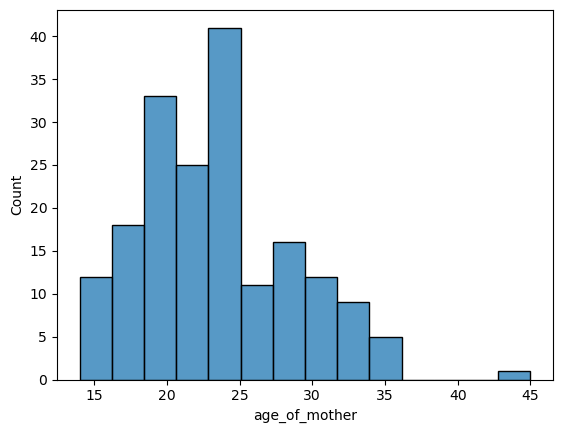

In [49]:
# Plot 'age_of_mother' column	
sns.histplot(data=df1,x='age_of_mother')

##  b) mothers menstrual weight

In [50]:
#Calculate the mean of 'last_menstrual_weight'
df1['last_menstrual_weight'].mean()

130.0928961748634

<Axes: xlabel='last_menstrual_weight', ylabel='Count'>

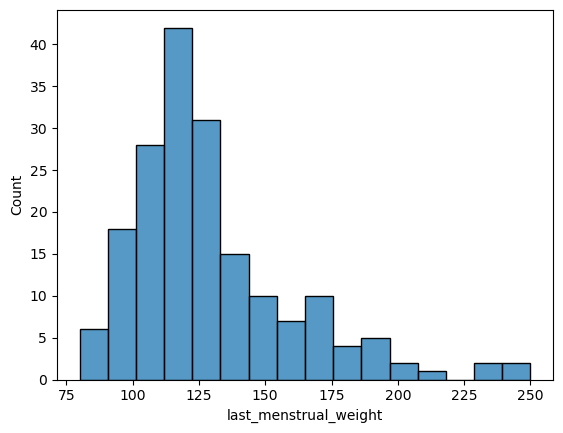

In [51]:
# Plot 'last_menstrual_weight'	
sns.histplot(data=df1,x='last_menstrual_weight')

##  Categorical Value Counts and Unique Values

## univariate

In [52]:
#Count unique values 'low_birth_weight' (categorical variable)
df1['low_birth_weight'].nunique()

2

In [53]:
# count values for 'low_birth_weight'
df1['low_birth_weight'].value_counts()

low_birth_weight
False    124
True      59
Name: count, dtype: int64

<Axes: xlabel='low_birth_weight', ylabel='count'>

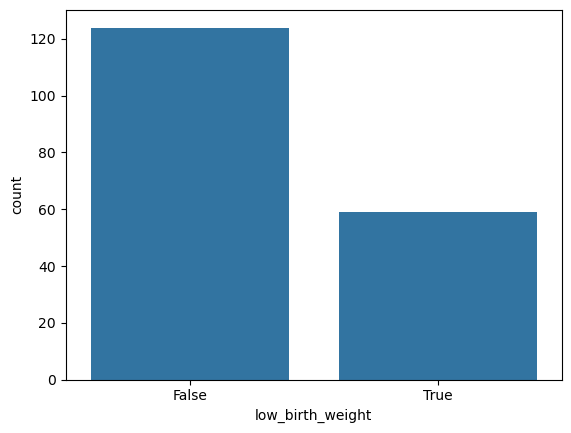

In [54]:
# Plot'low_birth_weight'(one categorical variable)
sns.countplot(data=df1, x='low_birth_weight')

In [55]:
#Count unique values 'smoking_status' (categorical variable)
df1['smoking_status'].nunique()

2

In [56]:
# count values for 'smoking_status'.
df1['smoking_status'].value_counts()

smoking_status
no     113
yes     70
Name: count, dtype: int64

<Axes: xlabel='smoking_status', ylabel='count'>

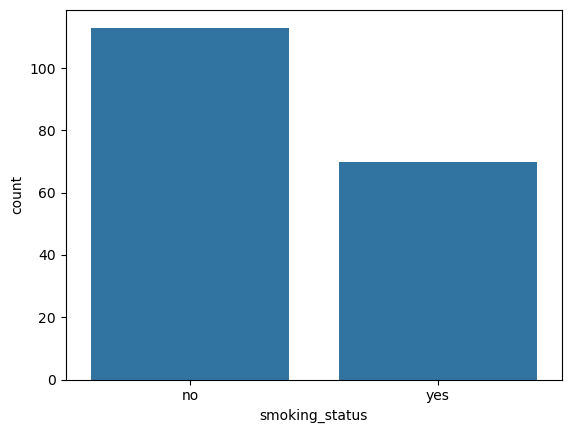

In [57]:
# Plot'smoking_status'(one categorical variable)
sns.countplot(data=df1, x='smoking_status')

In [58]:
df1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 183 entries, 0 to 182
Data columns (total 10 columns):
 #   Column                 Non-Null Count  Dtype 
---  ------                 --------------  ----- 
 0   low_birth_weight       183 non-null    bool  
 1   age_of_mother          183 non-null    int64 
 2   last_menstrual_weight  183 non-null    int64 
 3   mother_race            183 non-null    object
 4   smoking_status         183 non-null    object
 5   hypertension_history   183 non-null    object
 6   uterine_irritability   183 non-null    object
 7   physician_visit        183 non-null    object
 8   premature_labors       183 non-null    object
 9   age_category           183 non-null    object
dtypes: bool(1), int64(2), object(7)
memory usage: 13.2+ KB


In [59]:
#Count unique values 'mother_race' (categorical variable)
df1['mother_race'].nunique()

3

In [60]:
# count values for 'mother_race'.
df1['mother_race'].value_counts()

mother_race
White    92
Other    66
Black    25
Name: count, dtype: int64

<Axes: xlabel='mother_race', ylabel='count'>

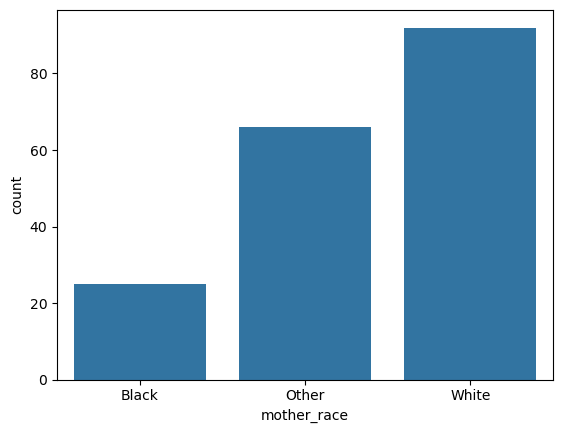

In [61]:
# Plot 'mother_race'(one categorical variable)
sns.countplot(data=df1, x='mother_race')

In [62]:
# Count unique values in 'hypertension_history' (categorical variable)
df1['hypertension_history'].nunique()

2

In [63]:
# Count values for 'hypertension_history'
df1['hypertension_history'].value_counts()

hypertension_history
no     171
yes     12
Name: count, dtype: int64

<Axes: xlabel='hypertension_history', ylabel='count'>

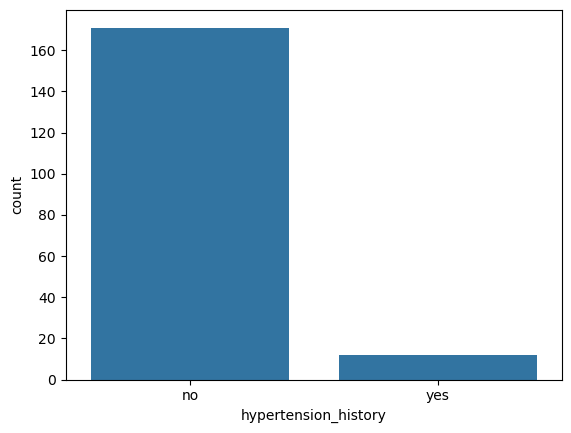

In [64]:
# Plot 'hypertension_history' (one categorical variable)
sns.countplot(data=df1, x='hypertension_history')

In [65]:
# Count unique values in 'uterine_irritability' (categorical variable)
df1['uterine_irritability'].nunique()

2

In [66]:
# Count values for 'uterine_irritability'
df1['uterine_irritability'].value_counts()

uterine_irritability
no     156
yes     27
Name: count, dtype: int64

<Axes: xlabel='uterine_irritability', ylabel='count'>

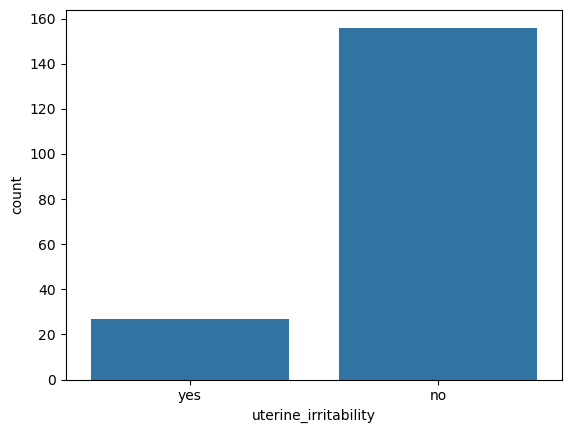

In [67]:
# Plot 'uterine_irritability' (one categorical variable)
sns.countplot(data=df1, x='uterine_irritability')

In [68]:
# Count unique values in 'physician_visit' (categorical variable)
df1['physician_visit'].nunique()

2

In [69]:
# Count values for 'physician_visit'
df1['physician_visit'].value_counts()

physician_visit
no     95
yes    88
Name: count, dtype: int64

<Axes: xlabel='physician_visit', ylabel='count'>

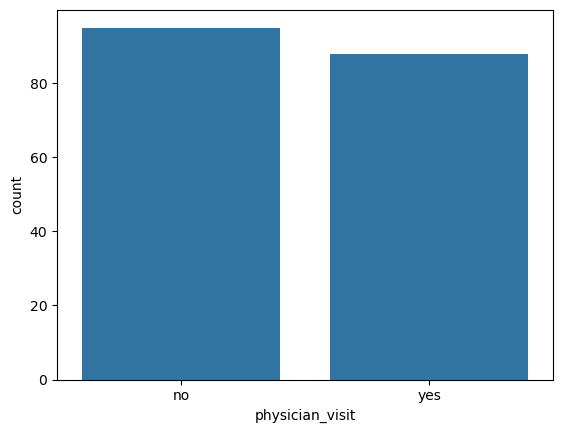

In [70]:
# Plot 'physician_visit' (one categorical variable)
sns.countplot(data=df1, x='physician_visit')

In [71]:
# Count unique values in 'premature_labors' (categorical variable)
df1['premature_labors'].nunique()

2

In [72]:
# Count values for 'premature_labors'
df1['premature_labors'].value_counts()

premature_labors
no     153
yes     30
Name: count, dtype: int64

<Axes: xlabel='premature_labors', ylabel='count'>

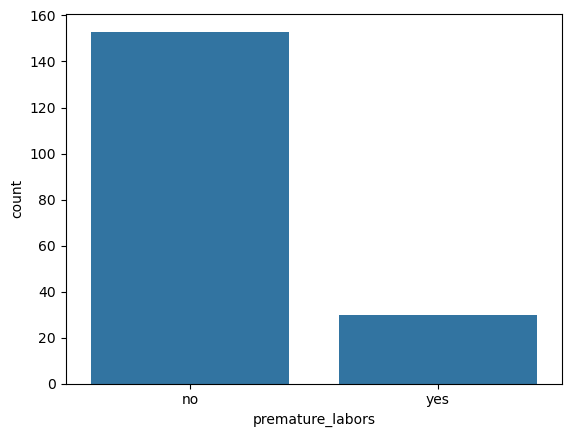

In [73]:
# Plot 'premature_labors' (one categorical variable)
sns.countplot(data=df1, x='premature_labors')

In [74]:
# Count unique values in 'age_category' (categorical variable)
df1['age_category'].nunique()

3

In [75]:
# Count values for 'age_category'
df1['age_category'].value_counts()

age_category
Young Adult     92
Mature Adult    46
Teen            45
Name: count, dtype: int64

<Axes: xlabel='age_category', ylabel='count'>

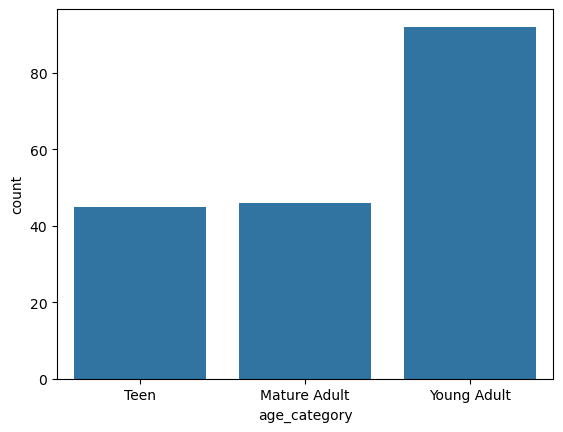

In [76]:
# Plot 'age_category' (one categorical variable)
sns.countplot(data=df1, x='age_category')

## SORTING (Groupby Target Variable 'low_birth_weight)"

In [77]:
# Show first/last rows, sorted by low_birth_weight
df.sort_values('low_birth_weight')

,low_birth_weight,age_of_mother,last_menstrual_weight,mother_race,smoking_status,hypertension_history,uterine_irritability,physician_visit,premature_labors,age_category
0,False,19,182,Black,no,no,yes,no,no,Teen
95,False,29,135,White,no,no,no,yes,no,Mature Adult
93,False,25,95,White,yes,no,yes,no,yes,Young Adult
92,False,19,235,White,yes,yes,no,no,no,Teen
91,False,21,134,Other,no,no,no,yes,no,Young Adult
...,...,...,...,...,...,...,...,...,...,...
154,True,24,138,White,no,no,no,no,no,Young Adult
155,True,17,130,Other,yes,no,yes,no,yes,Teen
156,True,20,120,Black,yes,no,no,yes,no,Young Adult
158,True,27,130,Black,no,no,yes,no,no,Mature Adult


## Categorical bivariate 

## a)smoking_status & low_birth_weight

In [78]:
# Calculate the percentage distribution of low_birth_weight categories for each smoking_status group
df1.groupby('smoking_status')['low_birth_weight'].value_counts(normalize=True)*100

smoking_status  low_birth_weight
no              False               74.336283
                True                25.663717
yes             False               57.142857
                True                42.857143
Name: proportion, dtype: float64

<Axes: xlabel='smoking_status', ylabel='count'>

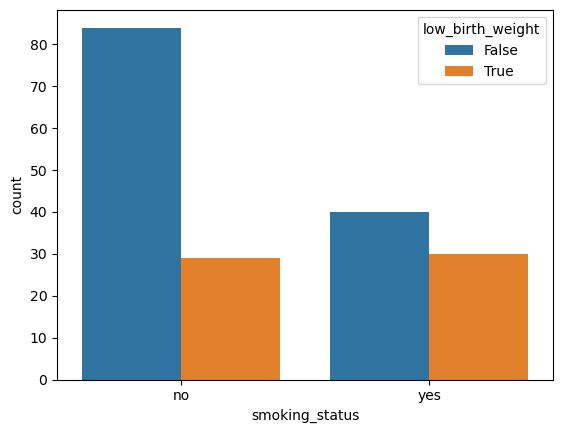

In [79]:
# Plot day and 'low_birth_weight and smoking_status' (two categorical variables)
sns.countplot(data=df1, x='smoking_status',hue='low_birth_weight')

# B) mother_race & low_birth_weight

In [80]:
# count values for 'mother_race'
df1['mother_race'].value_counts()

mother_race
White    92
Other    66
Black    25
Name: count, dtype: int64

In [81]:
# Count unique values in low_birth_weight'(categorical variable) for each unique value in 'mother_race' (categorical variable)
df1.groupby('mother_race')['low_birth_weight'].value_counts()

mother_race  low_birth_weight
Black        False               14
             True                11
Other        False               41
             True                25
White        False               69
             True                23
Name: count, dtype: int64

<Axes: xlabel='mother_race', ylabel='count'>

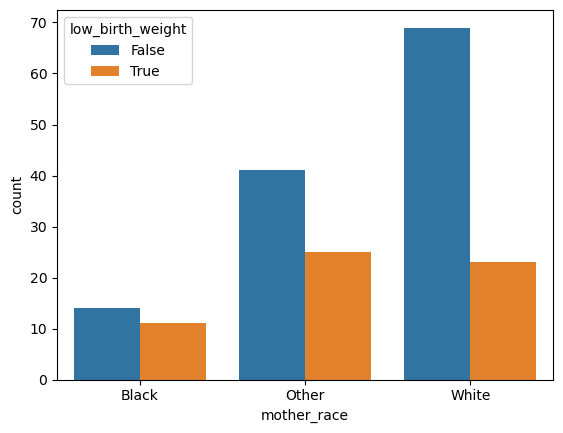

In [82]:
# Plot 'mother_race and 'low_birth_weight' (two categorical variables)
sns.countplot(data=df1, x='mother_race',hue='low_birth_weight')

##  low_birth_weights & uterine_irritability

In [83]:
# count values for 'uterine_irritability'
df1['uterine_irritability'].value_counts()

uterine_irritability
no     156
yes     27
Name: count, dtype: int64

<Axes: xlabel='uterine_irritability', ylabel='count'>

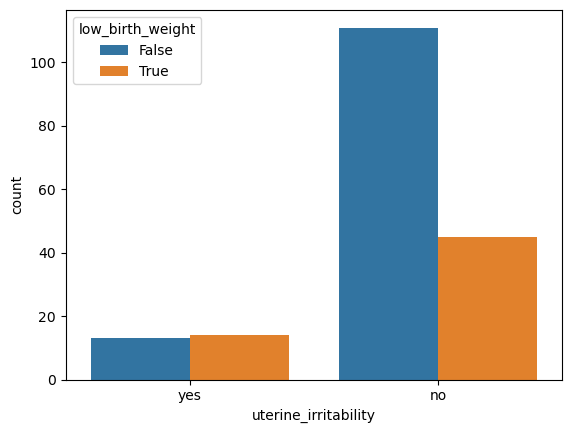

In [84]:
# Plot 'uterine_irritability and 'low_birth_weight' (two categorical variables)
sns.countplot(data=df1, x='uterine_irritability',hue='low_birth_weight')

## premature_labors & low_birth_weight

In [85]:
# count values for 'premature_labors'
df1['premature_labors'].value_counts()

premature_labors
no     153
yes     30
Name: count, dtype: int64

<Axes: xlabel='premature_labors', ylabel='count'>

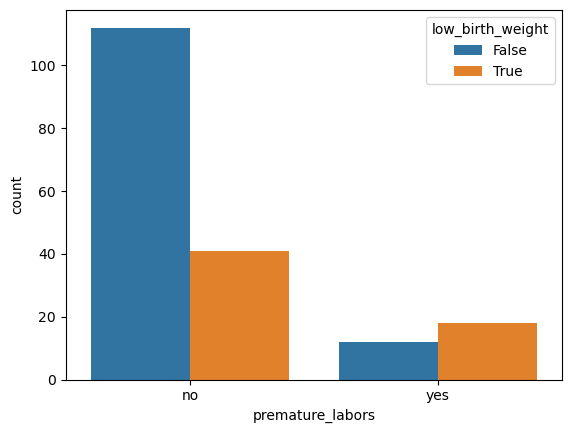

In [86]:
# Plot 'premature_labors and 'low_birth_weight (two categorical variables)
sns.countplot(data=df1, x='premature_labors',hue='low_birth_weight')

## physician_visit & low_birth_weight

In [87]:
# count values for 'physician_visit'
df1['physician_visit'].value_counts()

physician_visit
no     95
yes    88
Name: count, dtype: int64

<Axes: xlabel='physician_visit', ylabel='count'>

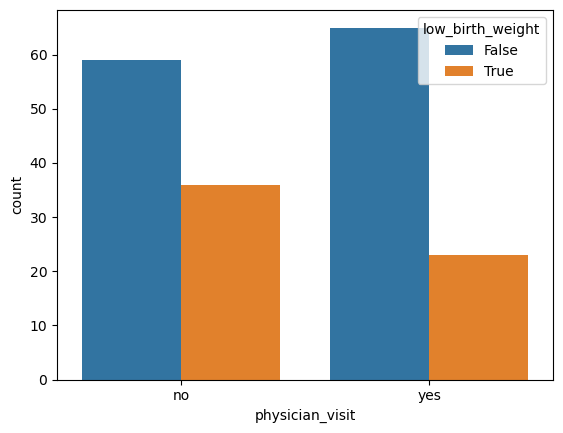

In [88]:
# Plot 'physician_visit  and 'low_birth_weight (two categorical variables)
sns.countplot(data=df1, x='physician_visit',hue='low_birth_weight')

## age_category & low_birth_weight

In [89]:
# count values for 'age_category'
df1['age_category'].value_counts()

age_category
Young Adult     92
Mature Adult    46
Teen            45
Name: count, dtype: int64

In [90]:
# Count unique values in low_birth_weight'(categorical variable) for each unique value in 'age_category' (categorical variable)
df1.groupby('age_category')['low_birth_weight'].value_counts(normalize=True)*100

age_category  low_birth_weight
Mature Adult  False               80.434783
              True                19.565217
Teen          False               66.666667
              True                33.333333
Young Adult   False               61.956522
              True                38.043478
Name: proportion, dtype: float64

<Axes: xlabel='age_category', ylabel='count'>

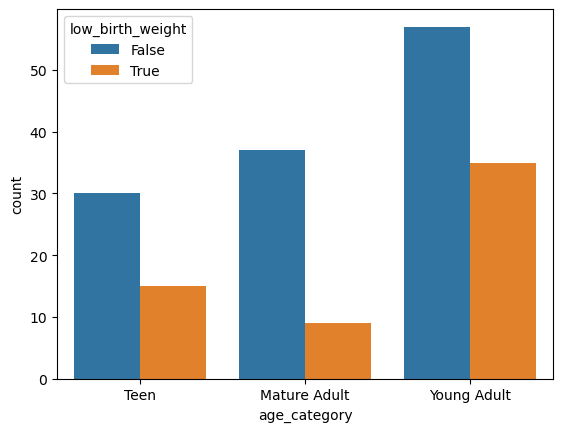

In [91]:
# Plot 'age_category' and 'low_birth_weight (two categorical variables)
sns.countplot(data=df1, x='age_category',hue='low_birth_weight')

## ONE CATEGORICAL ONE NUMERICAL

## 'low_birth_weight & age_of_mother

<Axes: xlabel='low_birth_weight', ylabel='age_of_mother'>

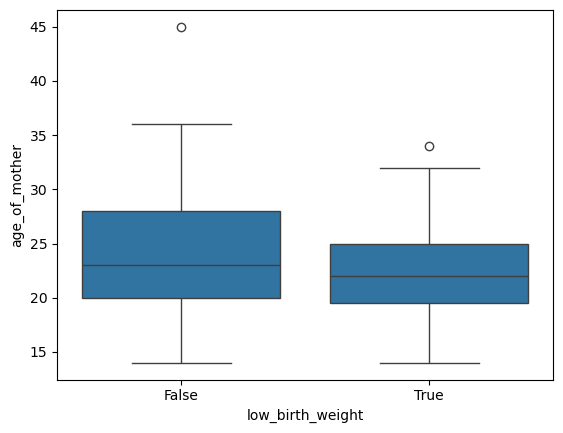

In [92]:
# Create a boxplot to visualize the distribution of age_of_mother across different low_birth_weight categories
sns.boxplot(data=df1, x='low_birth_weight', y='age_of_mother')

##  last_menstrual_weight	& 'low_birth_weight

<Axes: xlabel='low_birth_weight', ylabel='last_menstrual_weight'>

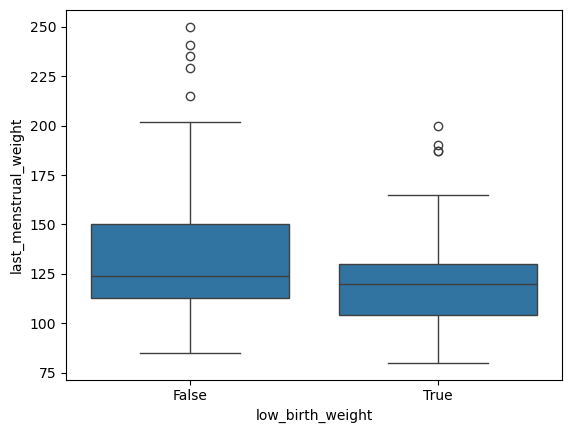

In [93]:
# Plot last_menstrual_weight and  'low_birth_weight (one categorical and one numerical variable)
sns.boxplot(data=df1, x='low_birth_weight', y='last_menstrual_weight' )

# Classification Analysis
#### Comparison of supervised machine learning models 

In [94]:
# import libraries: pandas and seaborn 
import pandas as pd
import seaborn as sns

In [95]:
# load 'Clean_MidtermReportPycats.csv' data 
df=pd.read_csv('low_birth_weight_project_clean.csv')

In [96]:
# Check the header 
df

,low_birth_weight,age_of_mother,last_menstrual_weight,mother_race,smoking_status,hypertension_history,uterine_irritability,physician_visit,premature_labors,age_category
0,False,19,182,Black,no,no,yes,no,no,Teen
1,False,33,155,Other,no,no,no,yes,no,Mature Adult
2,False,20,105,White,yes,no,no,yes,no,Young Adult
3,False,21,108,White,yes,no,yes,yes,no,Young Adult
4,False,18,107,White,yes,no,yes,no,no,Teen
...,...,...,...,...,...,...,...,...,...,...
178,True,28,95,White,yes,no,no,yes,no,Mature Adult
179,True,14,100,Other,no,no,no,yes,no,Teen
180,True,23,94,Other,yes,no,no,no,no,Young Adult
181,True,17,142,Black,no,yes,no,no,no,Teen


In [97]:
# Check data info()
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 183 entries, 0 to 182
Data columns (total 10 columns):
 #   Column                 Non-Null Count  Dtype 
---  ------                 --------------  ----- 
 0   low_birth_weight       183 non-null    bool  
 1   age_of_mother          183 non-null    int64 
 2   last_menstrual_weight  183 non-null    int64 
 3   mother_race            183 non-null    object
 4   smoking_status         183 non-null    object
 5   hypertension_history   183 non-null    object
 6   uterine_irritability   183 non-null    object
 7   physician_visit        183 non-null    object
 8   premature_labors       183 non-null    object
 9   age_category           183 non-null    object
dtypes: bool(1), int64(2), object(7)
memory usage: 13.2+ KB


In [98]:
#drop 'age_of_mother'
df=df.drop(columns='age_of_mother')

In [99]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 183 entries, 0 to 182
Data columns (total 9 columns):
 #   Column                 Non-Null Count  Dtype 
---  ------                 --------------  ----- 
 0   low_birth_weight       183 non-null    bool  
 1   last_menstrual_weight  183 non-null    int64 
 2   mother_race            183 non-null    object
 3   smoking_status         183 non-null    object
 4   hypertension_history   183 non-null    object
 5   uterine_irritability   183 non-null    object
 6   physician_visit        183 non-null    object
 7   premature_labors       183 non-null    object
 8   age_category           183 non-null    object
dtypes: bool(1), int64(1), object(7)
memory usage: 11.7+ KB


In [100]:
# Check the count of unique values
cat_cols = df.select_dtypes('object')
for i in cat_cols:
    print(df[i].value_counts(normalize=True))
    print('-' * 30)

mother_race
White    0.502732
Other    0.360656
Black    0.136612
Name: proportion, dtype: float64
------------------------------
smoking_status
no     0.617486
yes    0.382514
Name: proportion, dtype: float64
------------------------------
hypertension_history
no     0.934426
yes    0.065574
Name: proportion, dtype: float64
------------------------------
uterine_irritability
no     0.852459
yes    0.147541
Name: proportion, dtype: float64
------------------------------
physician_visit
no     0.519126
yes    0.480874
Name: proportion, dtype: float64
------------------------------
premature_labors
no     0.836066
yes    0.163934
Name: proportion, dtype: float64
------------------------------
age_category
Young Adult     0.502732
Mature Adult    0.251366
Teen            0.245902
Name: proportion, dtype: float64
------------------------------


In [101]:
# check descriptive stats
df.describe().T

,count,mean,std,min,25%,50%,75%,max
last_menstrual_weight,183.0,130.092896,30.86406,80.0,110.0,121.0,140.5,250.0


### Data Preprocessing 

#### One-HotEncoding 

In [102]:
# one-hot encoding 
# pd.get_dummies(, drop_first=True) 
df=pd.get_dummies(data=df, drop_first=True)

In [103]:
# check first/last rows 
df

,low_birth_weight,last_menstrual_weight,mother_race_Other,mother_race_White,smoking_status_yes,hypertension_history_yes,uterine_irritability_yes,physician_visit_yes,premature_labors_yes,age_category_Teen,age_category_Young Adult
0,False,182,False,False,False,False,True,False,False,True,False
1,False,155,True,False,False,False,False,True,False,False,False
2,False,105,False,True,True,False,False,True,False,False,True
3,False,108,False,True,True,False,True,True,False,False,True
4,False,107,False,True,True,False,True,False,False,True,False
...,...,...,...,...,...,...,...,...,...,...,...
178,True,95,False,True,True,False,False,True,False,False,False
179,True,100,True,False,False,False,False,True,False,True,False
180,True,94,True,False,True,False,False,False,False,False,True
181,True,142,False,False,False,True,False,False,False,True,False


In [104]:
# check data info()
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 183 entries, 0 to 182
Data columns (total 11 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   low_birth_weight          183 non-null    bool 
 1   last_menstrual_weight     183 non-null    int64
 2   mother_race_Other         183 non-null    bool 
 3   mother_race_White         183 non-null    bool 
 4   smoking_status_yes        183 non-null    bool 
 5   hypertension_history_yes  183 non-null    bool 
 6   uterine_irritability_yes  183 non-null    bool 
 7   physician_visit_yes       183 non-null    bool 
 8   premature_labors_yes      183 non-null    bool 
 9   age_category_Teen         183 non-null    bool 
 10  age_category_Young Adult  183 non-null    bool 
dtypes: bool(10), int64(1)
memory usage: 3.3 KB


In [105]:
# Create correlation matrix with numerical variables only
corr_mat=df[['low_birth_weight', 'last_menstrual_weight']].corr()

<Axes: >

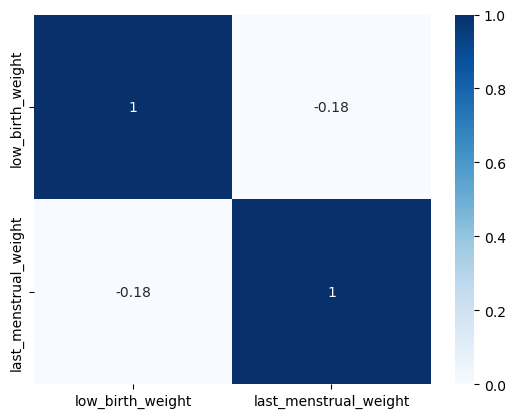

In [106]:
# Create a heatmap for correlation matrix 
sns.heatmap(corr_mat, annot=True, cmap='Blues', vmin=0, vmax=1)

### Correlation Analysis: `low_birth_weight` and `last_menstrual_weight`

The correlation coefficient of **-0.18** indicates a weak negative relationship between `low_birth_weight` and `last_menstrual_weight`. This suggests that as the `last_menstrual_weight` increases, there might be a slight decrease in the likelihood of `low_birth_weight`, but the relationship is not strong.

### Key Insights:
- **Magnitude**: Since the coefficient is closer to 0 than to -1, the relationship is weak.
- **Direction**: The negative sign shows an inverse relationship, meaning higher `last_menstrual_weight` is slightly associated with lower odds of `low_birth_weight`.

#### Check the target attribute

In [107]:
# 'low_birth_weight' - what percent of births had low birth weight?
df['low_birth_weight'].value_counts(normalize=True)

low_birth_weight
False    0.677596
True     0.322404
Name: proportion, dtype: float64

<Axes: xlabel='low_birth_weight', ylabel='count'>

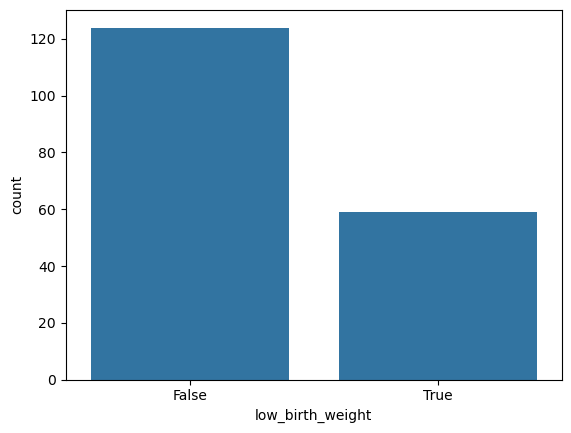

In [108]:
# 'low_birth_weight' - create a countplot using sns.countplot()
sns.countplot(data=df, x='low_birth_weight')

### Target Variable Distribution: `low_birth_weight`

The proportions indicate the following distribution of the target variable `low_birth_weight`:

- **False (Not low birth weight)**: ~67.8% of cases
- **True (Low birth weight)**: ~32.2% of cases

### Insights:
- The data is slightly imbalanced, with more births classified as `False` (not low birth weight) than `True`.
- This imbalance could affect the performance of classification models, as they may become biased toward predicting the majority class (`False`).


## Modeling

In [109]:
# Define the target, y
y=df['low_birth_weight']

In [110]:
# Define input attributes, X
X=df.drop(columns='low_birth_weight')

In [111]:
# Check x header 
X.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 183 entries, 0 to 182
Data columns (total 10 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   last_menstrual_weight     183 non-null    int64
 1   mother_race_Other         183 non-null    bool 
 2   mother_race_White         183 non-null    bool 
 3   smoking_status_yes        183 non-null    bool 
 4   hypertension_history_yes  183 non-null    bool 
 5   uterine_irritability_yes  183 non-null    bool 
 6   physician_visit_yes       183 non-null    bool 
 7   premature_labors_yes      183 non-null    bool 
 8   age_category_Teen         183 non-null    bool 
 9   age_category_Young Adult  183 non-null    bool 
dtypes: bool(9), int64(1)
memory usage: 3.2 KB


#### Scaling

In [112]:
# Import StandardScaler from sklearn.preprocessing
from sklearn.preprocessing import StandardScaler

In [113]:
# Initialize the StandardScaler
st_scaler=StandardScaler()
st_scaler

StandardScaler()

In [114]:
# From X, scaling numerical attributes: last_menstrual_weight
for_st_scaler=X.select_dtypes('number')

In [115]:
for_st_scaler.head(2)

,last_menstrual_weight
0,182
1,155


In [116]:
# assign the name, scaled, to the array 
scaled=st_scaler.fit_transform(for_st_scaler)
scaled

array([[ 1.68641163e+00],
       [ 8.09207728e-01],
       [-8.15243942e-01],
       [-7.17776842e-01],
       [-7.50265875e-01],
       [-1.97952307e-01],
       [-3.92886508e-01],
       [-8.80222009e-01],
       [-2.30441341e-01],
       [-5.55331675e-01],
       [-1.14013428e+00],
       [ 6.46762561e-01],
       [-1.14013428e+00],
       [-7.50265875e-01],
       [-9.77689109e-01],
       [-1.04266718e+00],
       [-3.92886508e-01],
       [-3.27908441e-01],
       [-3.27908441e-01],
       [-9.45200076e-01],
       [-9.77689109e-01],
       [ 2.33619230e+00],
       [-3.27908441e-01],
       [-3.27908441e-01],
       [ 1.19907613e+00],
       [-2.62930374e-01],
       [ 6.46762561e-01],
       [ 1.23156516e+00],
       [-5.55331675e-01],
       [-1.30257944e+00],
       [-2.95419408e-01],
       [ 8.09207728e-01],
       [-1.65463274e-01],
       [ 3.21872227e-01],
       [ 2.56894160e-01],
       [-1.97952307e-01],
       [ 2.75854973e+00],
       [-6.85287809e-01],
       [ 1.7

In [117]:
# Assign the scaled values back to the X DataFrame
X[['last_menstrual_weight']]=scaled

In [118]:
X

,last_menstrual_weight,mother_race_Other,mother_race_White,smoking_status_yes,hypertension_history_yes,uterine_irritability_yes,physician_visit_yes,premature_labors_yes,age_category_Teen,age_category_Young Adult
0,1.686412,False,False,False,False,True,False,False,True,False
1,0.809208,True,False,False,False,False,True,False,False,False
2,-0.815244,False,True,True,False,False,True,False,False,True
3,-0.717777,False,True,True,False,True,True,False,False,True
4,-0.750266,False,True,True,False,True,False,False,True,False
...,...,...,...,...,...,...,...,...,...,...
178,-1.140134,False,True,True,False,False,True,False,False,False
179,-0.977689,True,False,False,False,False,True,False,True,False
180,-1.172623,True,False,True,False,False,False,False,False,True
181,0.386850,False,False,False,True,False,False,False,True,False


#### Modeling

In [119]:
# import train_test_split from sklearn.model_selection 
from sklearn.model_selection import train_test_split

In [120]:
# split train and test dataset (80% vs 20%); include stratify=y
X_train, X_test, y_train, y_test=train_test_split(X,y, test_size=0.2, random_state=42, stratify=y)

In [121]:
# import LogisticRegression from sklearn.linear_model 
from sklearn.linear_model import LogisticRegression

In [122]:
# initialize the logr 
logr=LogisticRegression()

In [123]:
# fit model on train data 
logr.fit(X_train, y_train)

LogisticRegression()

#### Prediction - Apply the model to the Test Dataset 

In [124]:
# prediction based on X_test  
pred_logr=logr.predict(X_test)
pred_logr

array([ True, False, False, False, False,  True, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False,  True, False, False, False,  True, False,  True, False,
       False,  True, False,  True, False, False, False,  True, False,
        True])

#### Model evaluation 

In [125]:
# actual value of y
y_test

124     True
37     False
99     False
14     False
103    False
160     True
146     True
21     False
102    False
71     False
20     False
178     True
145     True
112    False
2      False
167     True
23     False
51     False
52     False
74     False
87     False
92     False
123    False
29     False
110    False
60     False
82     False
1      False
158     True
86     False
150     True
108    False
163     True
106    False
147     True
171     True
177     True
Name: low_birth_weight, dtype: bool

In [126]:
#predicted value of y 
pred_logr

array([ True, False, False, False, False,  True, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False,  True, False, False, False,  True, False,  True, False,
       False,  True, False,  True, False, False, False,  True, False,
        True])

In [127]:
# Create a data frame for comparison: actual (y_test) vs predicted value of y
comparison=pd.DataFrame({'Actual':y_test, 'Predicted':pred_logr})

In [128]:
# check the first 10 rows of the data frame 
comparison.head(10)

,Actual,Predicted
124,True,True
37,False,False
99,False,False
14,False,False
103,False,False
160,True,True
146,True,False
21,False,False
102,False,False
71,False,False


In [129]:
# check the intercept 
logr.intercept_

array([-1.1013977])

In [130]:
# check coefficients
coefficient=logr.coef_.T

In [131]:
# Create a coefficient data frame
coefficient=pd.DataFrame(coefficient, columns=['coefficient'], index=X.columns)

In [132]:
# create a column for absolute coefficients 
coefficient['abs_coefficient']=coefficient['coefficient'].abs()

In [133]:
# sort coefficients based on its absolute size, in a descending order 
coefficient.sort_values('abs_coefficient', ascending=False).head(10)

,coefficient,abs_coefficient
hypertension_history_yes,1.105618,1.105618
mother_race_White,-0.960147,0.960147
premature_labors_yes,0.806335,0.806335
smoking_status_yes,0.794520,0.794520
age_category_Young Adult,0.647865,0.647865
uterine_irritability_yes,0.511594,0.511594
physician_visit_yes,-0.300056,0.300056
last_menstrual_weight,-0.231114,0.231114
mother_race_Other,-0.188178,0.188178
age_category_Teen,0.002877,0.002877


### Model Evaluation 

In [134]:
# from sklearn.metrics import classification_report, accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay 
from sklearn.metrics import classification_report, accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

              precision    recall  f1-score   support

       False       0.79      0.88      0.83        25
        True       0.67      0.50      0.57        12

    accuracy                           0.76        37
   macro avg       0.73      0.69      0.70        37
weighted avg       0.75      0.76      0.75        37



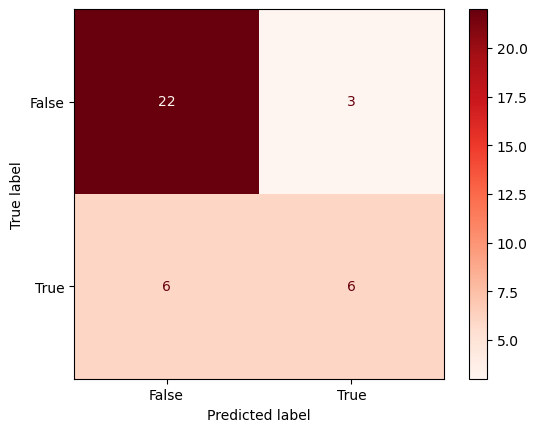

In [135]:
# print classification_report 
print(classification_report(y_test, pred_logr))
# display ConfusionMatrixDisplay 
ConfusionMatrixDisplay.from_predictions(y_test, pred_logr, cmap='Reds')

In [136]:
# import precision_recall_curve from sklearn.metrics 
from sklearn.metrics import precision_recall_curve

In [137]:
# predict_proba gives the probability of each observation belonging to each class
pred_proba=logr.predict_proba(X_test)
pred_proba

array([[0.28932642, 0.71067358],
       [0.80356114, 0.19643886],
       [0.5450473 , 0.4549527 ],
       [0.73850074, 0.26149926],
       [0.84530295, 0.15469705],
       [0.47738394, 0.52261606],
       [0.64946771, 0.35053229],
       [0.94792193, 0.05207807],
       [0.81584107, 0.18415893],
       [0.86308841, 0.13691159],
       [0.83535282, 0.16464718],
       [0.78643698, 0.21356302],
       [0.89546152, 0.10453848],
       [0.83725605, 0.16274395],
       [0.67498124, 0.32501876],
       [0.65965932, 0.34034068],
       [0.58768119, 0.41231881],
       [0.76375376, 0.23624624],
       [0.75691273, 0.24308727],
       [0.39908886, 0.60091114],
       [0.72533941, 0.27466059],
       [0.80076751, 0.19923249],
       [0.90956566, 0.09043434],
       [0.4530976 , 0.5469024 ],
       [0.89046639, 0.10953361],
       [0.28144284, 0.71855716],
       [0.74993845, 0.25006155],
       [0.85528284, 0.14471716],
       [0.34226773, 0.65773227],
       [0.80775811, 0.19224189],
       [0.

In [138]:
# define precision, recall, thresholds 
precision, recall, thresholds=precision_recall_curve(y_test, pred_proba[:,[1]])

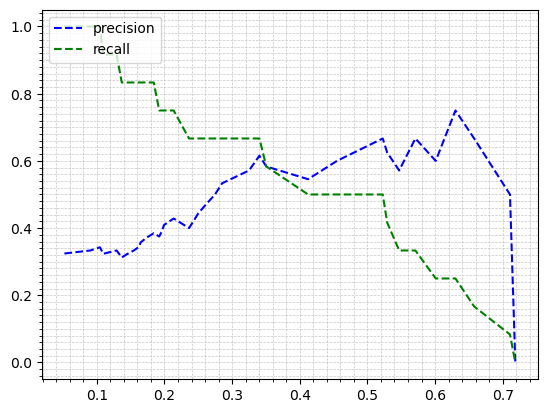

In [139]:
# Let' draw a precision and recall curve to find out the optimal thresholds 
import matplotlib.pyplot as plt 
# Plot values of precisions, recalls, and thresholds
plt.grid(True, which='both', linestyle='--', linewidth=0.5, alpha=0.7)
plt.plot(thresholds, precision[:-1], 'b--', label = 'precision')
plt.plot(thresholds, recall[:-1], 'g--', label = 'recall')
plt.gca().xaxis.set_minor_locator(plt.MultipleLocator(0.02))
plt.gca().yaxis.set_minor_locator(plt.MultipleLocator(0.02))
plt.legend(loc = 'upper left')

In [140]:
# Make a prediction of y based on the optimal threshold, 0.34
pred_logr2 = pred_proba[:, [1]] >= 0.34

In [141]:
pred_logr2

array([[ True],
       [False],
       [ True],
       [False],
       [False],
       [ True],
       [ True],
       [False],
       [False],
       [False],
       [False],
       [False],
       [False],
       [False],
       [False],
       [ True],
       [ True],
       [False],
       [False],
       [ True],
       [False],
       [False],
       [False],
       [ True],
       [False],
       [ True],
       [False],
       [False],
       [ True],
       [False],
       [ True],
       [False],
       [False],
       [False],
       [ True],
       [False],
       [ True]])

              precision    recall  f1-score   support

       False       0.83      0.80      0.82        25
        True       0.62      0.67      0.64        12

    accuracy                           0.76        37
   macro avg       0.72      0.73      0.73        37
weighted avg       0.76      0.76      0.76        37



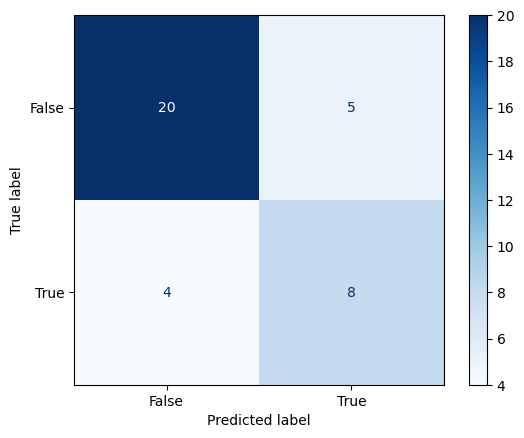

In [142]:
#print classification report 
print(classification_report(y_test, pred_logr2))
# display ConfusionMatrixDisplay 
ConfusionMatrixDisplay.from_predictions(y_test, pred_logr2, cmap='Blues')

### Decision Tree Classification 

In [143]:
# from sklearn.tree import DecisionTreeClassifier
from sklearn.tree import DecisionTreeClassifier

In [144]:
# Initialize decision tree classifier
dtc=DecisionTreeClassifier()

In [145]:
# Fit a decision tree classification model on the training data
dtc.fit(X_train, y_train)

DecisionTreeClassifier()

In [146]:
# Use the fitted model to make predictions on the testing data
pred_dtc=dtc.predict(X_test)
pred_dtc

array([False,  True,  True,  True, False,  True, False, False, False,
       False,  True, False,  True, False,  True, False, False, False,
       False,  True, False, False, False, False,  True, False,  True,
       False,  True, False,  True, False, False, False, False, False,
       False])

              precision    recall  f1-score   support

       False       0.68      0.68      0.68        25
        True       0.33      0.33      0.33        12

    accuracy                           0.57        37
   macro avg       0.51      0.51      0.51        37
weighted avg       0.57      0.57      0.57        37



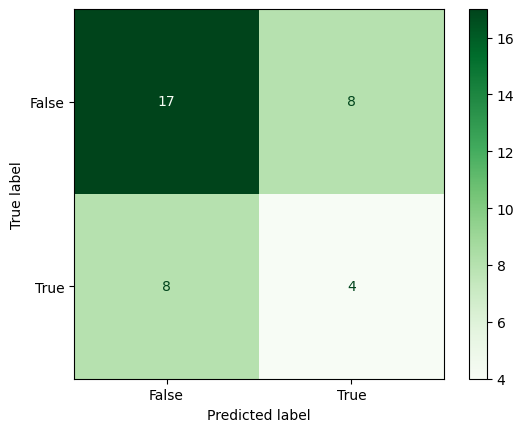

In [147]:
# Print classification report 
print(classification_report(y_test, pred_dtc))
# Display ConfusionMatrixDisplay from_predictions 
ConfusionMatrixDisplay.from_predictions(y_test, pred_dtc, cmap='Greens')

##### Let's Plot the Tree 

In [148]:
# import tree from sklearn 
from sklearn import tree

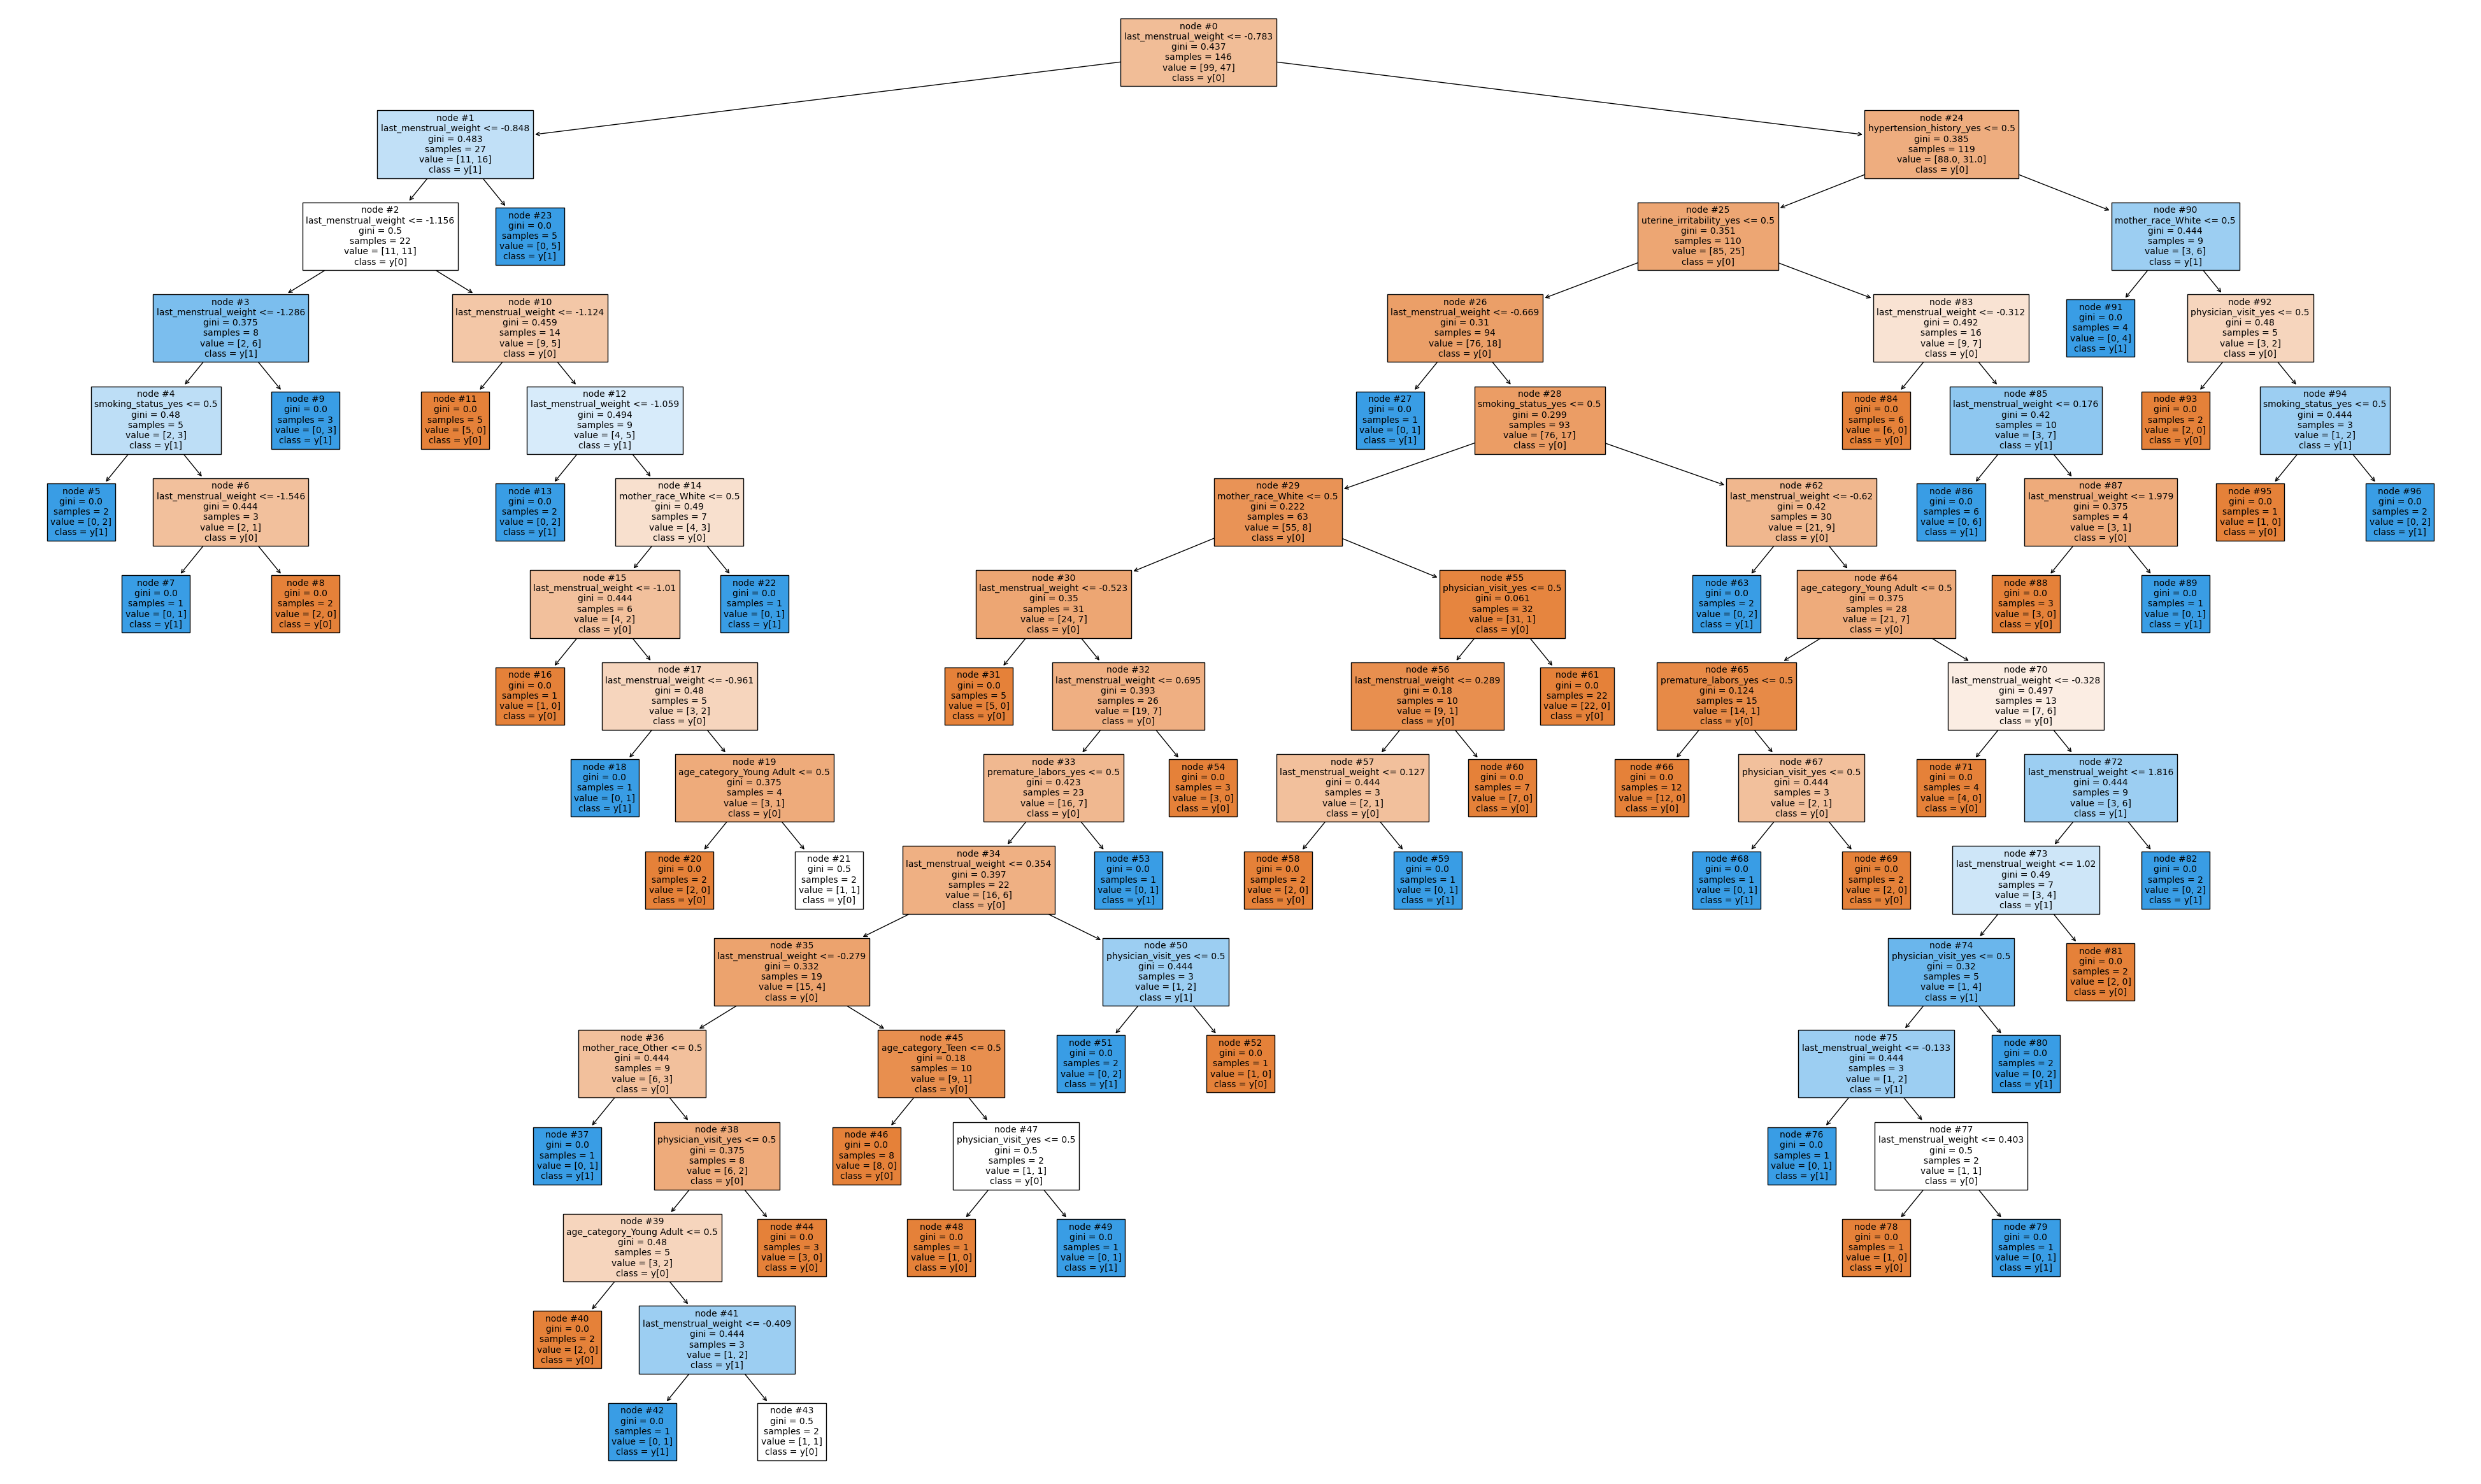

In [149]:
# plot the tree 
# import matplotlib.pyplot as plt 
import matplotlib.pyplot as plt
# set the size of the figure 
plt.figure(figsize=(50,30))
# plot_tree() with model, feature_names, filled, node=ids, class_names, fontsize
tree.plot_tree(dtc, feature_names=X.columns, filled=True, node_ids=True, class_names=True, fontsize=10)
# show the plot 
plt.show()

**Let's plot the feature importance and check the most important features.**

In [150]:
# check the feature_importances_
Importances=dtc.feature_importances_

In [151]:
# Create a data frame for feature_importances_
# sort values by 'importances' in a descending order 
Importances=pd.DataFrame(Importances, columns=['importance'], index=X.columns).sort_values('importance', ascending=False)
Importances

,importance
last_menstrual_weight,0.597356
physician_visit_yes,0.092930
age_category_Young Adult,0.060552
smoking_status_yes,0.058580
mother_race_White,0.057563
hypertension_history_yes,0.052031
uterine_irritability_yes,0.026806
premature_labors_yes,0.025028
mother_race_Other,0.016197
age_category_Teen,0.012958


(0.0, 1.0)

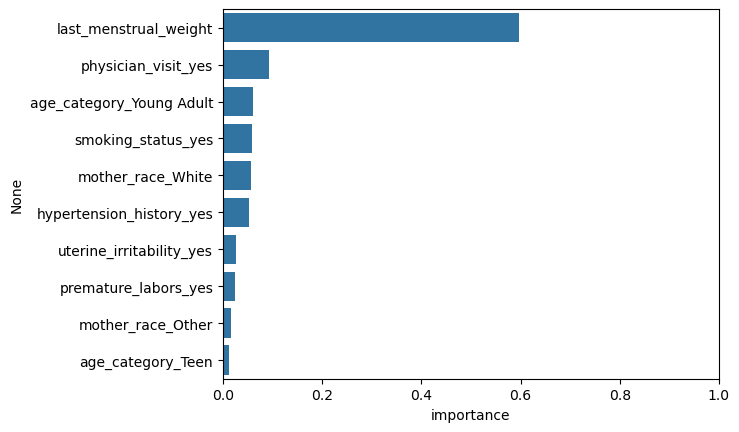

In [152]:
# Plot the feature_importances_ using sns
import seaborn as sns
sns.barplot(x=Importances.importance, y=Importances.index)
plt.xlim([0,1])

### Decision Tree: Hyperparameter Tuned Model

In [153]:
# For hyperparameter tuning # import GridSearchCV from sklearn.model_selection 
from sklearn.model_selection import GridSearchCV

In [154]:
# Grid of parameters to choose from
dtc = DecisionTreeClassifier()
weights = [{0:0.32, 1:0.68}, 'balanced', {0:0.5, 1:0.5}]
parameters ={'max_depth':[2,3,4,5,6,7,8,9],
             'min_samples_leaf':[2,5,10,20,25], 'criterion': ['gini','entropy'], 'class_weight': weights }

### Hyperparameter Tuning Description

- **Class weight**: The target variable `low_birth_weight` is imbalanced (e.g., ~67.8% of cases are non-low birth weight (`False`), and ~32.2% are low birth weight (`True`)). Without accounting for this imbalance, the decision tree might become biased toward predicting the majority class (`False`, non-low birth weight). Using `class_weight` (e.g., `{0:0.32, 1:0.68}`) helps the model give appropriate weight to the minority class (`True`, low birth weight), improving recall and F1-score for low birth weight predictions.

- **max_depth**: The `max_depth` hyperparameter controls how deep the decision tree grows. Features like `last_menstrual_weight` (continuous), and categorical predictors such as `mother_race`, `smoking_status`, and `age_category` contribute to decision splits. Restricting the depth prevents the model from overfitting to specific patterns within these features, ensuring better generalization.

- **criterion**: This dataset includes a mix of continuous (`last_menstrual_weight`) and boolean categorical features (e.g., `mother_race_Other`, `physician_visit_yes`). Testing both `gini` (Gini impurity) and `entropy` (information gain) ensures the model identifies the best splitting criterion for the data.

- **min_samples_leaf**: Setting `min_samples_leaf` ensures that the leaf nodes represent a reasonable number of cases. For this dataset, this prevents overly specific splits (e.g., rare combinations of `mother_race` and `smoking_status`) and ensures that the model generalizes well to unseen data.


In [155]:
# import metrics from sklearn
from sklearn import metrics
# Setting type of scoring (metrics.make_scorer) used to compare parameter combinations-f1_score for class 1 (pos_label)
scorer=metrics.make_scorer(f1_score, pos_label=1)

In [156]:
# set the GridSearchCV with estimator, param_grid, scoring, cv=5 (5 iterations)
gridCV=GridSearchCV(dtc, parameters, scoring=scorer, cv=5)

In [157]:
# fit gridCV on train data; # Set the classifier to the best combination of parameters(best_estimator_); save it as dtc_tuned
dtc_tuned=gridCV.fit(X_train, y_train).best_estimator_
dtc_tuned

DecisionTreeClassifier(class_weight={0: 0.5, 1: 0.5}, max_depth=4,
                       min_samples_leaf=5)

**Fit the best algorithm (dtc_tuned) to the data**

In [158]:
# predict y (pred_dtc2) on X_test 
pred_dtc2=dtc_tuned.predict(X_test)

              precision    recall  f1-score   support

       False       0.75      0.72      0.73        25
        True       0.46      0.50      0.48        12

    accuracy                           0.65        37
   macro avg       0.61      0.61      0.61        37
weighted avg       0.66      0.65      0.65        37



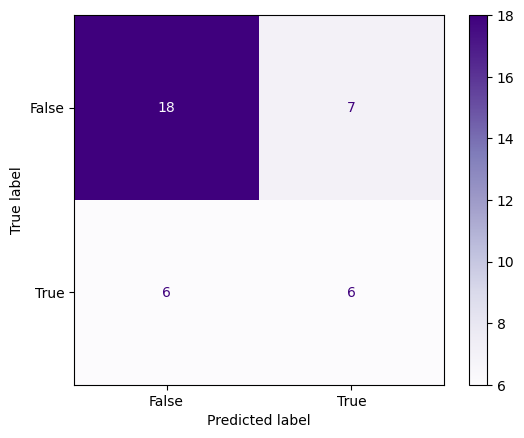

In [159]:
# print classification_report 
print(classification_report(y_test, pred_dtc2))
# display ConfusionMatrixDisplay 
ConfusionMatrixDisplay.from_predictions(y_test, pred_dtc2, cmap='Purples')

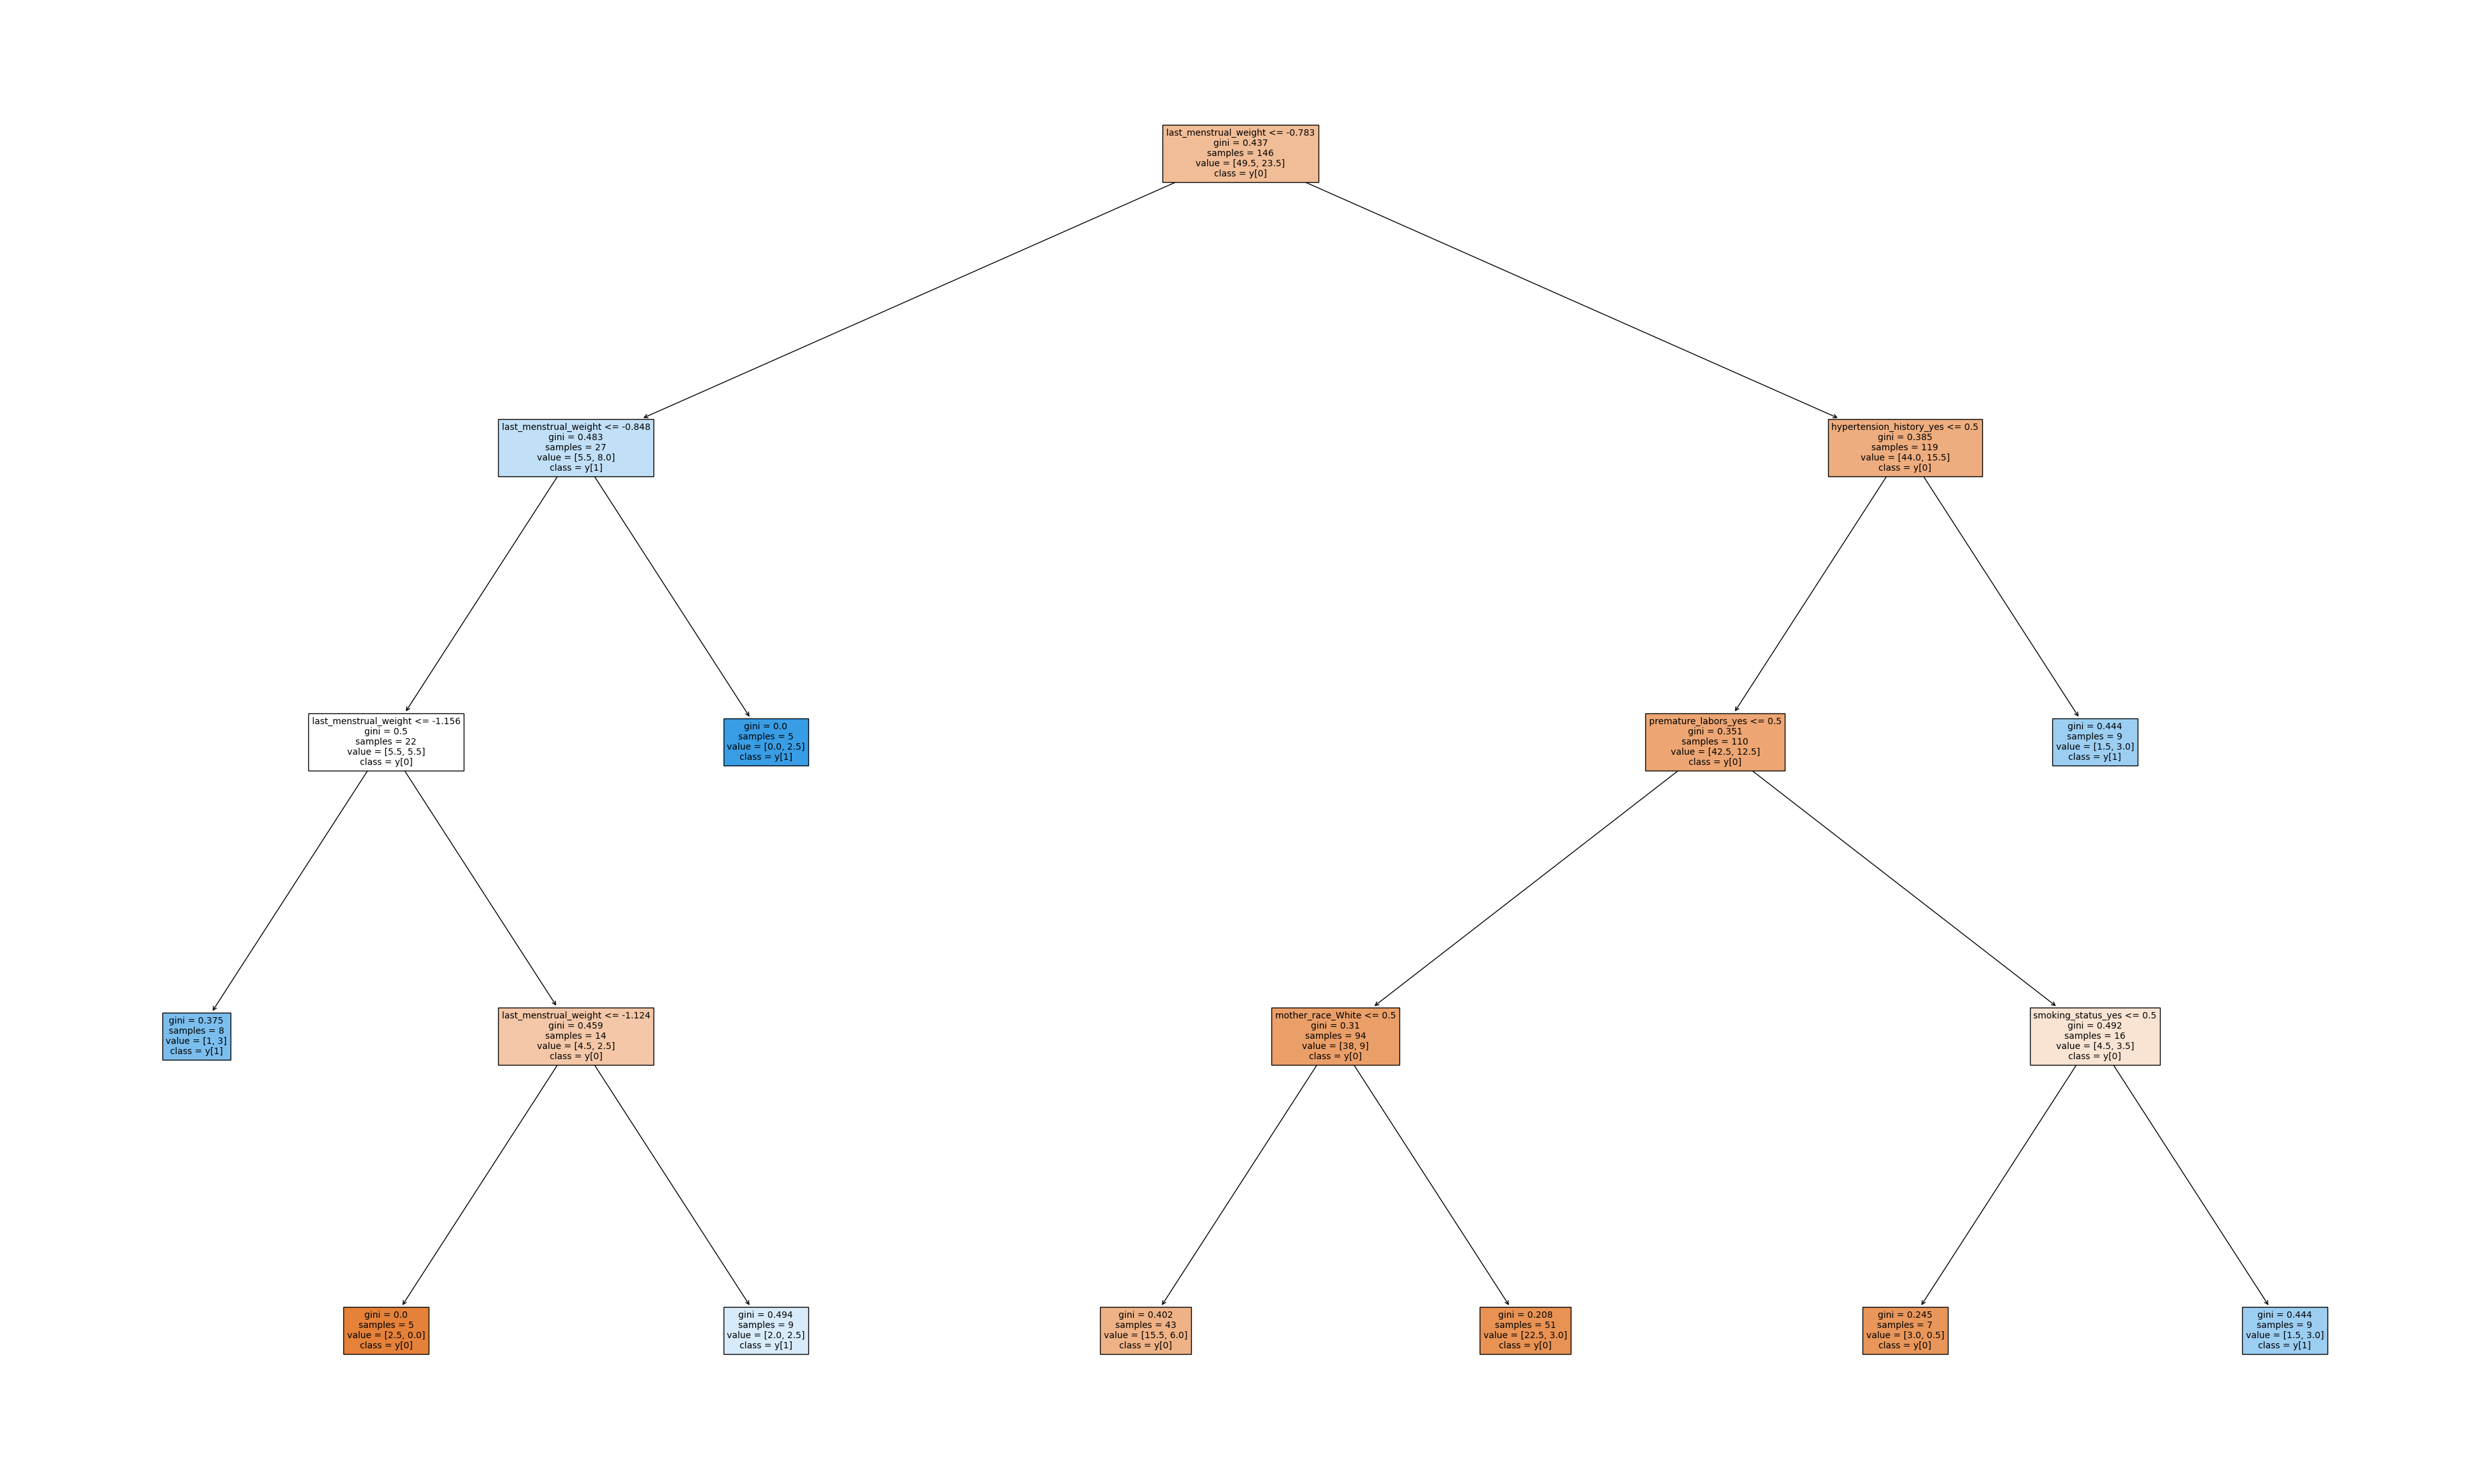

In [160]:
# plot the tree 
# set the size of the figure 
plt.figure(figsize=(50,30))
# tree.plot_tree() with model, feature_names, filled, node=ids, class_names, fontsize
tree.plot_tree(dtc_tuned, feature_names=X.columns, filled=True, class_names=True, fontsize=10)
# show the plot 
plt.show()

In [161]:
# check the feature_importances_
Importances=dtc_tuned.feature_importances_
Importances

array([0.5589245 , 0.        , 0.0650505 , 0.11560535, 0.17187272,
       0.        , 0.        , 0.08854693, 0.        , 0.        ])

In [162]:
# create a data frame, sort_values by 'Importance' in a descending order 
Importances=pd.DataFrame(Importances, columns=['importance'], index=X.columns).sort_values('importance', ascending=False)

In [163]:
# Create a data frame for feature_importances_
# sort values by 'importances' in a descending order 
Importances=pd.DataFrame(Importances, columns=['importance'], index=X.columns).sort_values('importance', ascending=False)
Importances

,importance
last_menstrual_weight,0.558925
hypertension_history_yes,0.171873
smoking_status_yes,0.115605
premature_labors_yes,0.088547
mother_race_White,0.065050
mother_race_Other,0.000000
uterine_irritability_yes,0.000000
physician_visit_yes,0.000000
age_category_Teen,0.000000
age_category_Young Adult,0.000000


(0.0, 1.0)

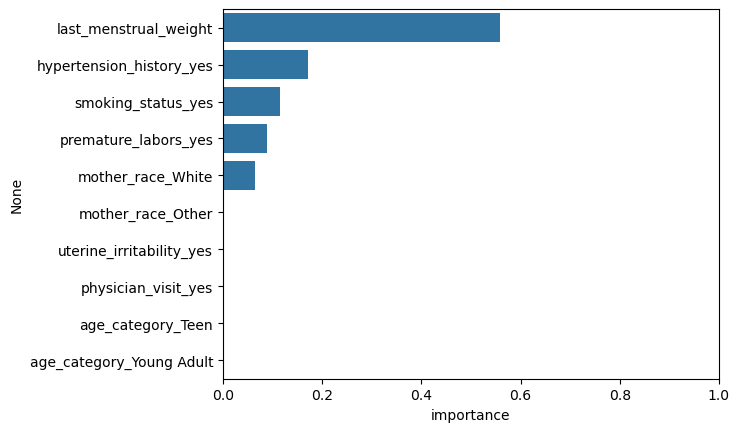

In [164]:
# Plot the feature_importances_ using sns; set x limits [0,1]
sns.barplot(x=Importances.importance, y=Importances.index)
plt.xlim([0,1])

### K-Nearest neighbor classification

In [165]:
# import KNeighborsClassifier from sklearn.neighbors 
from sklearn.neighbors import KNeighborsClassifier

In [166]:
# initialize KNeighborsClassifier
knc=KNeighborsClassifier()

In [167]:
# Fit k-nearest neighbors classification model on the training data
knc.fit(X_train, y_train)

KNeighborsClassifier()

In [168]:
# Use the fitted model to make predictions on the testing data
pred_knc=knc.predict(X_test)

              precision    recall  f1-score   support

       False       0.69      0.96      0.80        25
        True       0.50      0.08      0.14        12

    accuracy                           0.68        37
   macro avg       0.59      0.52      0.47        37
weighted avg       0.63      0.68      0.59        37



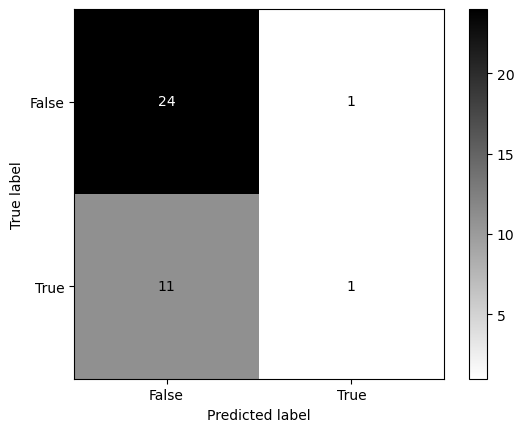

In [169]:
#print classification_report 
print(classification_report(y_test, pred_knc))
# Display ConfusionMatrixDisplay from_predictions 
ConfusionMatrixDisplay.from_predictions(y_test, pred_knc, cmap='binary')

## Conclusions

In [170]:
# Calculate the f1 score (an indicator of the model performance) for each model 
f1_logr=f1_score(y_test, pred_logr)
f1_logr2=f1_score(y_test, pred_logr2)
f1_dtc=f1_score(y_test, pred_dtc)
f1_dtc2=f1_score(y_test, pred_dtc2)
f1_knc=f1_score(y_test, pred_knc)

In [171]:
# set the best_model 
best_model=max((f1_logr, 'Logistic Regression'),(f1_logr2,'Logistic Regression with the Optimal Thresholds, 0.34'),(f1_dtc,'Decision Tree Classifier'),(f1_dtc2,'Decision Tree Classifier Hypterparameter Tuned'),(f1_knc,'KNeighbors Classifier'))

In [172]:
# print the best model
print(f'The best model is {best_model[1]} with f1_score of {best_model[0]}')

The best model is Logistic Regression with the Optimal Thresholds, 0.34 with f1_score of 0.64


In [173]:
# Calculate the recall score (an indicator of the model performance)
recall_logr=recall_score(y_test, pred_logr)
recall_logr2=recall_score(y_test, pred_logr2)
recall_dtc=recall_score(y_test, pred_dtc)
recall_dtc2=recall_score(y_test, pred_dtc2)
recall_knc=recall_score(y_test, pred_knc)

In [174]:
# set the best_model 
best_model2=max((recall_logr, 'Logistic Regression'),(recall_logr2,'Logistic Regression with the Optimal Thresholds, 0.34'),(recall_dtc,'Decision Tree Classifier'),(recall_dtc2,'Decision Tree Classifier Hyperparameter Tuned'),(recall_knc,'KNeighbors Classifier'))

In [175]:
# print the best model 
print(f'The best model is {best_model2[1]} with recall_score of {best_model2[0]}')

The best model is Logistic Regression with the Optimal Thresholds, 0.34 with recall_score of 0.6666666666666666
